# Waste Classifier — Training & Evaluation

Klasifikasi gambar sampah ke **4 kelas**: `organic`, `paper`, `plastic`, dan `other`.

`other` = foto yang **bukan** salah satu dari 3 jenis sampah (kaca, logam, baterai, baju, sepatu, dan benda sehari-hari seperti gitar atau HP).
Tanpa kelas ini model 3 kelas selalu memaksa jawaban ke organik/kertas/plastik, misalnya foto gitar terbaca "99% kertas".
API mengubah hasil `other` menjadi *"tidak dikenali sebagai sampah"*.

- Dataset: 4 dataset Kaggle (lihat `dataset/README.md`), diproses oleh `scripts/prepare_dataset.py`: mapping kelas, hapus duplikat (perceptual hash), 2.500 gambar/kelas, split 70/15/15.
- Uji tambahan `unseen`: 8 jenis benda Caltech-101 (termasuk `electric_guitar`) yang **tidak pernah** dipakai saat training, untuk mengukur apakah `other` benar-benar general.
- Model: **MobileNetV2** (ImageNet) + transfer learning, input 224×224.
- Tahap 1: base dibekukan, hanya head yang dilatih. Tahap 2: fine-tune 60 layer terakhir dengan learning rate kecil.
- Output: `models/waste_classifier.keras`, `models/waste_classifier.tflite`, dan `reports/*`.


In [1]:
import json, os, random
from pathlib import Path

import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
REPORTS = ROOT / "reports"; REPORTS.mkdir(exist_ok=True)

IMG_SIZE = (224, 224)
BATCH = 32
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793945856.267744   34678 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793945856.301097   34678 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793945857.049103   34678 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load dataset

In [2]:
def load(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        DATA / split, image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="int", shuffle=shuffle, seed=SEED,
    )

train_ds = load("train", True)
val_ds = load("val", False)
test_ds = load("test", False)
# Object types never used in training (e.g. electric_guitar). All should be predicted "other".
unseen_ds = keras.utils.image_dataset_from_directory(
    DATA / "unseen" / "other", labels=None, image_size=IMG_SIZE, batch_size=BATCH, shuffle=False,
)
UNSEEN_FILES = unseen_ds.file_paths
CLASS_NAMES = train_ds.class_names
print("Classes:", CLASS_NAMES)
summary = json.loads((DATA / "summary.json").read_text())
print({c: {k: v for k, v in info.items() if k != "groups"} for c, info in summary["classes"].items()})
print("unseen:", summary["unseen_other"])

AUTOTUNE = tf.data.AUTOTUNE
# Cache to disk instead of RAM: ~10k decoded images would need ~6 GB of memory.
CACHE = ROOT / "data" / "cache"
import shutil; shutil.rmtree(CACHE, ignore_errors=True); CACHE.mkdir(parents=True)
train_ds = train_ds.cache(str(CACHE / "train")).prefetch(AUTOTUNE)
val_ds = val_ds.cache(str(CACHE / "val")).prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)
unseen_ds = unseen_ds.prefetch(AUTOTUNE)

Found 6867 files belonging to 4 classes.


I0000 00:00:1793945860.314321   34678 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4166 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 1471 files belonging to 4 classes.


Found 1474 files belonging to 4 classes.


Found 488 files.


Classes: ['organic', 'other', 'paper', 'plastic']
{'organic': {'total': 2311, 'train': 1617, 'val': 346, 'test': 348}, 'paper': {'total': 2500, 'train': 1750, 'val': 375, 'test': 375}, 'plastic': {'total': 2500, 'train': 1750, 'val': 375, 'test': 375}, 'other': {'total': 2501, 'train': 1750, 'val': 375, 'test': 376}}
unseen: {'cellphone': 59, 'electric_guitar': 75, 'headphone': 42, 'lamp': 61, 'laptop': 81, 'umbrella': 75, 'windsor_chair': 56, 'wrench': 39}


W0000 00:00:1793945861.310942   34964 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


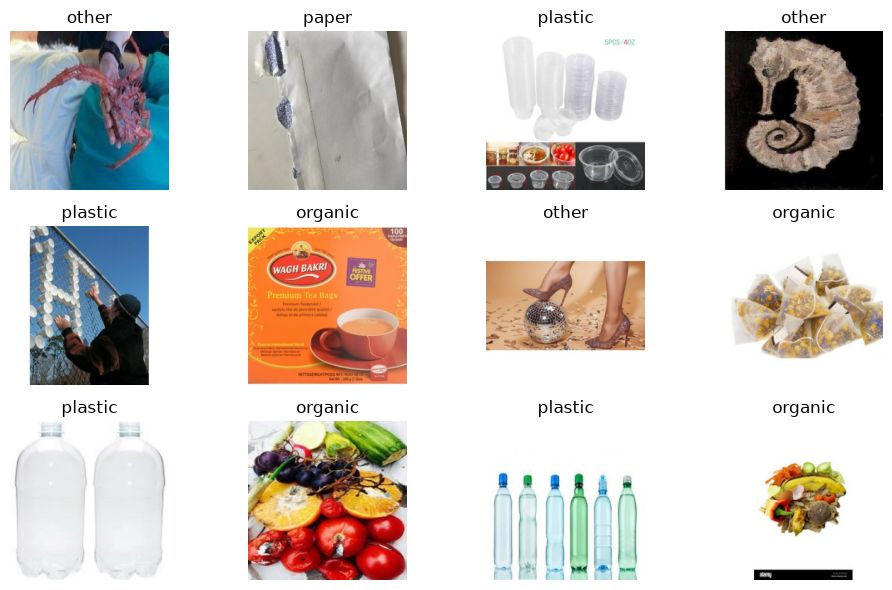

In [3]:
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[labels[i]])
        plt.axis("off")
plt.tight_layout(); plt.show()

## 2. Model

Preprocessing (scaling ke [-1, 1] sesuai MobileNetV2) dan augmentasi dimasukkan ke dalam model.
Jadi API cukup mengirim gambar RGB 224×224 dengan nilai 0–255. Layer augmentasi otomatis nonaktif saat inference.

Augmentasi dibuat mirip variasi foto HP: miring, objek tidak di tengah, zoom, terang/gelap, dan kontras berbeda.


In [4]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")

base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
x = augment(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="mobilenet_preprocess")(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax", name="probabilities")(x)
model = keras.Model(inputs, outputs, name="waste_classifier")
model.summary(show_trainable=True)

Model: "waste_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenet_preprocess        │ (None, 224, 224, 3)   │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ probabilities (Dense)       │ (None, 4)             │      5,124 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 3. Tahap 1: latih head (base dibekukan)

In [5]:
def callbacks(tag):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
        keras.callbacks.ModelCheckpoint(str(MODELS / f"checkpoint_{tag}.keras"), monitor="val_accuracy", save_best_only=True),
    ]

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=12, callbacks=callbacks("stage1"))

Epoch 1/12


/home/asadel/kuliah/lomba/smstr6/guido/dataset_rup/vinara-money-classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


I0000 00:00:1793945866.254662   34844 cuda_dnn.cc:461] Loaded cuDNN version 92400


  1/215 ━━━━━━━━━━━━━━━━━━━━ 14:52 4s/step - accuracy: 0.2812 - loss: 1.8310

  2/215 ━━━━━━━━━━━━━━━━━━━━ 13s 65ms/step - accuracy: 0.2500 - loss: 1.9423

  3/215 ━━━━━━━━━━━━━━━━━━━━ 14s 67ms/step - accuracy: 0.2500 - loss: 1.8519

... (2,587 outputs left out)

212/215 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8184 - loss: 0.4752

213/215 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8185 - loss: 0.4754

214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8178 - loss: 0.4771

215/215 ━━━━━━━━━━━━━━━━━━━━ 18s 85ms/step - accuracy: 0.8178 - loss: 0.4772 - val_accuracy: 0.8572 - val_loss: 0.4316 - learning_rate: 3.0000e-04


## 4. Tahap 2: fine-tune 60 layer terakhir

In [6]:
base.trainable = True
for layer in base.layers[:-60]:
    layer.trainable = False
# BatchNorm tetap dibekukan agar statistik ImageNet tidak rusak oleh batch kecil.
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
start = len(hist1.history["loss"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=start + 15, initial_epoch=start, callbacks=callbacks("stage2"))

Epoch 13/27


  1/215 ━━━━━━━━━━━━━━━━━━━━ 18:16 5s/step - accuracy: 0.8438 - loss: 0.4293

  2/215 ━━━━━━━━━━━━━━━━━━━━ 16s 79ms/step - accuracy: 0.8594 - loss: 0.4054

  3/215 ━━━━━━━━━━━━━━━━━━━━ 17s 81ms/step - accuracy: 0.8438 - loss: 0.4286

  4/215 ━━━━━━━━━━━━━━━━━━━━ 17s 82ms/step - accuracy: 0.8359 - loss: 0.4523

  5/215 ━━━━━━━━━━━━━━━━━━━━ 17s 84ms/step - accuracy: 0.8125 - loss: 0.4813

... (3,245 outputs left out)

213/215 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9306 - loss: 0.1941

214/215 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9303 - loss: 0.1944

215/215 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9305 - loss: 0.1941

215/215 ━━━━━━━━━━━━━━━━━━━━ 22s 102ms/step - accuracy: 0.9305 - loss: 0.1941 - val_accuracy: 0.9035 - val_loss: 0.3082 - learning_rate: 1.0000e-05


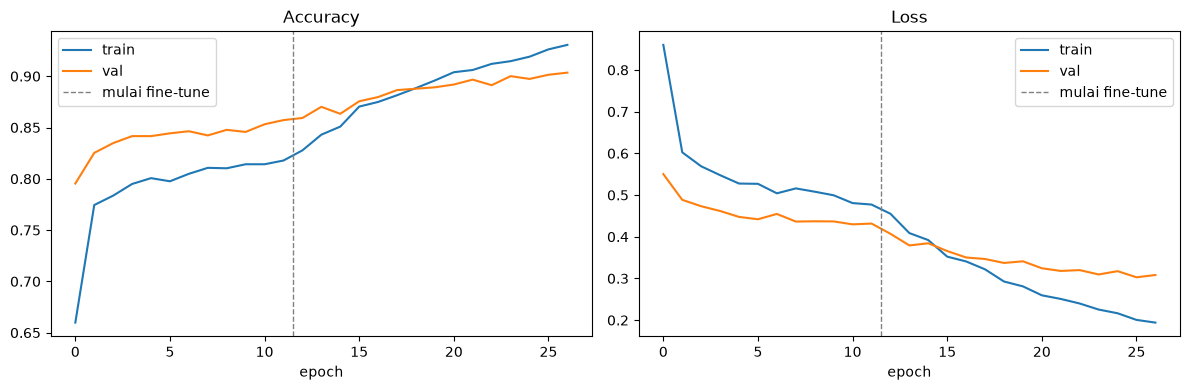

In [7]:
history = {k: hist1.history[k] + hist2.history[k] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.plot(history[metric], label="train")
    ax.plot(history["val_" + metric], label="val")
    ax.axvline(start - 0.5, color="gray", ls="--", lw=1, label="mulai fine-tune")
    ax.set_title(metric.capitalize()); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(REPORTS / "training_curves.png", dpi=120); plt.show()

## 5. Evaluasi pada test set (data yang tidak pernah dilihat saat training)

In [8]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

test_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_acc:.4f}  ({(y_true == y_pred).sum()}/{len(y_true)})")

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report)
(REPORTS / "classification_report.txt").write_text(f"Test accuracy: {test_acc:.4f}\n\n{report}")

Test accuracy: 0.9132  (1346/1474)
              precision    recall  f1-score   support

     organic     0.9527    0.9253    0.9388       348
       other     0.8759    0.9202    0.8975       376
       paper     0.9301    0.9227    0.9264       375
     plastic     0.8997    0.8853    0.8925       375

    accuracy                         0.9132      1474
   macro avg     0.9146    0.9134    0.9138      1474
weighted avg     0.9139    0.9132    0.9133      1474



457

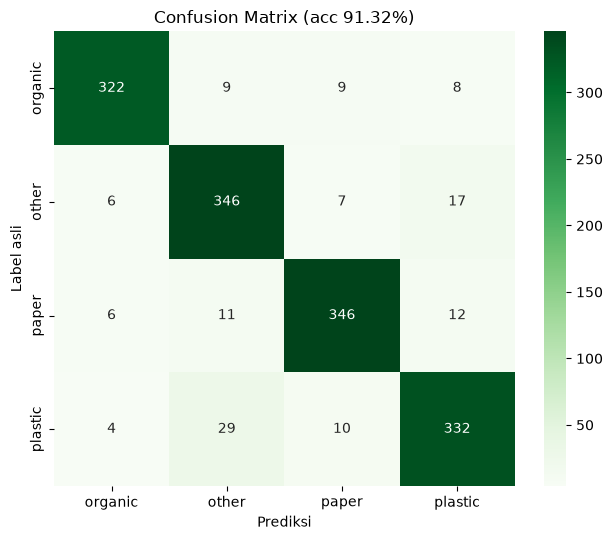

In [9]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Prediksi"); plt.ylabel("Label asli"); plt.title(f"Confusion Matrix (acc {test_acc:.2%})")
plt.tight_layout(); plt.savefig(REPORTS / "confusion_matrix.png", dpi=120); plt.show()

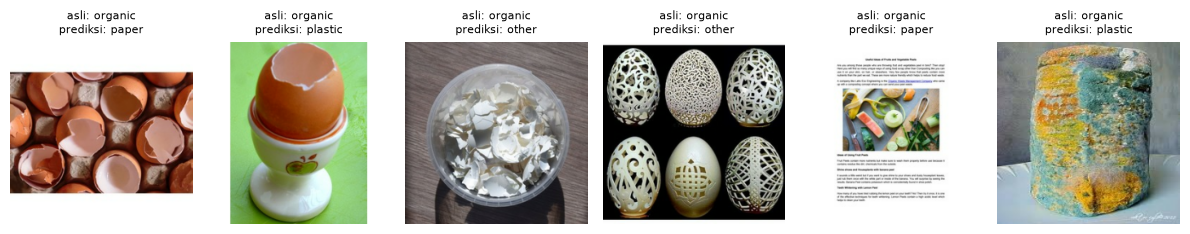

128 prediksi salah dari 1474


In [10]:
# Contoh prediksi yang salah, untuk analisis kelas yang sering tertukar.
wrong = np.where(y_true != y_pred)[0]
images = np.concatenate([x.numpy() for x, _ in test_ds])
plt.figure(figsize=(12, 3))
for i, idx in enumerate(wrong[:6]):
    plt.subplot(1, 6, i + 1)
    plt.imshow(images[idx].astype("uint8"))
    plt.title(f"asli: {CLASS_NAMES[y_true[idx]]}\nprediksi: {CLASS_NAMES[y_pred[idx]]}", fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()
print(f"{len(wrong)} prediksi salah dari {len(y_true)}")

### Uji benda yang tidak pernah dilihat (`unseen`)
Jenis benda ini sengaja **tidak** dimasukkan ke train/val/test. Model yang baik harus menjawab `other`.
Yang paling penting: berapa persen yang **lolos** sebagai sampah (organic/paper/plastic).


In [11]:
from collections import Counter, defaultdict

OTHER = CLASS_NAMES.index("other")
unseen_pred = model.predict(unseen_ds, verbose=0).argmax(axis=1)
unseen_other_rate = float((unseen_pred == OTHER).mean())
print(f"Unseen -> other: {unseen_other_rate:.2%} ({(unseen_pred == OTHER).sum()}/{len(unseen_pred)})")

by_cat = defaultdict(Counter)
for path, pred in zip(UNSEEN_FILES, unseen_pred):
    cat = Path(path).name.split("_image_")[0].replace("caltech-101_", "")
    by_cat[cat][CLASS_NAMES[pred]] += 1
unseen_by_category = {}
for cat, cnt in sorted(by_cat.items()):
    total = sum(cnt.values())
    unseen_by_category[cat] = round(cnt["other"] / total, 4)
    print(f"  {cat:15s} other={cnt['other']:3d}/{total:3d} ({cnt['other']/total:.0%})  lolos sebagai sampah: {dict((k, v) for k, v in cnt.items() if k != 'other')}")


Unseen -> other: 87.70% (428/488)
  cellphone       other= 45/ 59 (76%)  lolos sebagai sampah: {'plastic': 12, 'paper': 2}
  electric_guitar other= 72/ 75 (96%)  lolos sebagai sampah: {'plastic': 3}
  headphone       other= 42/ 42 (100%)  lolos sebagai sampah: {}
  lamp            other= 53/ 61 (87%)  lolos sebagai sampah: {'plastic': 2, 'organic': 3, 'paper': 3}
  laptop          other= 65/ 81 (80%)  lolos sebagai sampah: {'paper': 16}
  umbrella        other= 60/ 75 (80%)  lolos sebagai sampah: {'paper': 13, 'plastic': 2}
  windsor_chair   other= 56/ 56 (100%)  lolos sebagai sampah: {}
  wrench          other= 35/ 39 (90%)  lolos sebagai sampah: {'plastic': 2, 'organic': 2}


## 6. Simpan model + metrik

In [12]:
keras_path = MODELS / "waste_classifier.keras"
model.save(keras_path)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_path = MODELS / "waste_classifier.tflite"
tflite_path.write_bytes(converter.convert())

(MODELS / "labels.json").write_text(json.dumps(CLASS_NAMES))

per_class = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
metrics = {
    "model": "MobileNetV2 transfer learning",
    "input_size": list(IMG_SIZE),
    "classes": CLASS_NAMES,
    "test_accuracy": round(float(test_acc), 4),
    "test_samples": int(len(y_true)),
    "per_class": {c: {k: round(v, 4) for k, v in per_class[c].items()} for c in CLASS_NAMES},
    "macro_f1": round(per_class["macro avg"]["f1-score"], 4),
    "confusion_matrix": cm.tolist(),
    "epochs_trained": len(history["loss"]),
    "unseen_other_rate": round(unseen_other_rate, 4),
    "unseen_samples": int(len(unseen_pred)),
    "unseen_by_category": unseen_by_category,
}
(REPORTS / "metrics.json").write_text(json.dumps(metrics, indent=2))

for f in MODELS.glob("checkpoint_*.keras"):
    f.unlink()
print(json.dumps({k: metrics[k] for k in ["test_accuracy", "macro_f1", "unseen_other_rate", "epochs_trained"]}))
print(f"keras: {keras_path.stat().st_size/1e6:.1f} MB | tflite: {tflite_path.stat().st_size/1e6:.1f} MB")

INFO:tensorflow:Assets written to: /tmp/tmp8k1t09ci/assets


INFO:tensorflow:Assets written to: /tmp/tmp8k1t09ci/assets


Saved artifact at '/tmp/tmp8k1t09ci'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  140687431249424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431251536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431252496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431252112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431251344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431252304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431251920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431253648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431253264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431252688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140687431252880: Tens

{"test_accuracy": 0.9132, "macro_f1": 0.9138, "unseen_other_rate": 0.877, "epochs_trained": 27}
keras: 25.2 MB | tflite: 2.5 MB


W0000 00:00:1793946436.407050   34678 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793946436.407074   34678 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793946436.407330   34678 reader.cc:83] Reading SavedModel from: /tmp/tmp8k1t09ci
I0000 00:00:1793946436.413059   34678 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793946436.413071   34678 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp8k1t09ci
I0000 00:00:1793946436.468372   34678 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793946436.482826   34678 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793946436.937005   34678 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp8k1t09ci
I0000 00:00:1793946437.040708   34678 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 633387 microseconds.
I0000 00:00:1793946437.166117   3467

In [13]:
# Cek: TFLite memberi hasil yang sama dengan model Keras.
interp = tf.lite.Interpreter(model_path=str(tflite_path))
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
agree = 0
for i in range(len(images)):
    interp.set_tensor(inp["index"], images[i : i + 1].astype(np.float32))
    interp.invoke()
    agree += int(interp.get_tensor(out["index"]).argmax() == y_pred[i])
print(f"TFLite vs Keras agreement: {agree}/{len(images)}")

/home/asadel/kuliah/lomba/smstr6/guido/dataset_rup/vinara-money-classifier/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


TFLite vs Keras agreement: 1457/1474
